# Spatial Clustering of the Fibre Centroids — Ripley's K and Log-Gaussian Cox Process

The fibre centroids of a roving cross-section are treated as a planar point pattern in the ROI window:

1. **Point pattern** — centroids from the `.h5` instances, ROI as observation window, intensity λ;
   window erosion check (the ROI hugs the fibre outlines → no centroids in the outer band)
2. **Intensity map** — edge-corrected kernel estimate λ(x) and profile along the roving: where are fibres denser / sparser?
3. **Nearest neighbour G(r)** — short range: hard core of touching fibres (regularity)
4. **Ripley's K, L(r) − r, pair correlation g(r)** — vs. complete spatial randomness (CSR) **and hard-core CSR**
   (random packing, minimum distance one fibre diameter) with simulation envelopes and a global MAD test
5. **Directional K** — along (x) vs. across (y) the roving
6. **LGCP fit** — log-Gaussian Cox process Λ(x) = λ·exp(Z(x) − σ²/2), Z Gaussian field with covariance
   σ²·exp(−r/ℓ), fitted by minimum contrast to g and K on the long-range part (r ≥ `R_MIN`)
7. **LGCP goodness of fit** — envelopes of the fitted LGCP
7b. **Bundle model** — hard-core fibres in the excursion set of a Gaussian field (clipped LGCP): fibre bundles +
   resin pockets, fitted by simulation over the *full* r range
8. **Quadrat dispersion** — Var/mean of counts vs. quadrat size: data vs. CSR vs. LGCP vs. bundle model
9. **Two-point correlation of the fibre phase** — S2, C2 = S2 − φ², integral range, local-V_f variance, link to g(r),
   check of the models on descriptors not used in any fit
10. **Summary**

**Interpretation.** Fibres cannot overlap, so at short distances the pattern is *regular* (g ≈ 0 below one fibre
diameter, oscillations from the packing).  Clustering is a long-range effect: fibre-rich bundles and resin-rich
regions → g(r) > 1 and L(r) − r > 0 at r of a few diameters and more.  The LGCP models exactly this intensity
fluctuation: **σ²** = variance of the log intensity (clustering strength), **ℓ** = correlation length (size of
clusters / resin pockets).  An LGCP has no hard core, so it is only fitted and tested for r ≥ `R_MIN`, and it
overestimates the count variance (section 8).  The bundle model (7b) adds the hard core and describes all scales.

Estimators (translation edge correction with the set covariance of the mask window) are in
`sam2.addons.point_patterns`.

In [ ]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sam2.addons import (
    read_instance_centroids, window_mask_from_image,
    MaskWindow, k_function, l_function, pair_correlation, nn_distances, nn_function, envelope, quadrat_dispersion,
    lgcp_pcf, lgcp_k, fit_lgcp_mincontrast, simulate_lgcp, kernel_intensity,
    gaussian_random_field, simulate_hardcore_cox, excursion_log_field, boundary_profile, fit_by_simulation,
    s2_window, radial_profile, integral_range, box_fraction_variance, box_variance_from_c2, c2_from_pcf,
    render_disks,
)

h5_path = Path("../../results/dataset_veit/results_02/Tape_1.h5")       # raw analyse.py output (no mask, no px size)
# h5_path = Path("../../results/Promotion/160/batch_02/160-02_01.h5")         # specimen h5 with ROI mask + px size

# microscope calibration (µm/px per objective); raw analyse.py output has no pixel size → set MAGNIFICATION
UM_PER_PX = {"2.5x": 2.30119, "5x": 1.17426, "10x": 0.584173, "20x": 0.293018, "50x": 0.116887, "100x": 0.0583594}
MAGNIFICATION = "20x"  # Veit tapes; only used if the h5 has no pixel size (specimen h5 like 01.h5 carry their own)
MIN_AREA_FRAC = 0.4    # drop instances smaller than this × median area (fragments)

# all scales in fibre diameters Ø (→ comparable between magnifications)
WIN_ERODE_D = 0.7      # shrink the window by ≈ fibre radius + margin (centroid domain), see 1b
R_MAX_D     = 20       # max. distance of K / g (capped where < R_MAX_COV of the window still contributes pairs)
R_MAX_COV   = 0.2
R_MIN_D     = 4        # LGCP fit / test range starts here (beyond the packing shells)
KDE_SIGMA_D = 2        # bandwidth of the intensity map
X_BIN_D     = 7        # slice width of the intensity profile along x
A_SIZES_D   = np.array([1.2, 1.7, 2.3, 3.5, 4.6, 7, 9.2, 14])   # quadrat sides
N_R         = 150
N_SIM       = 39       # simulations per null model → pointwise 95 % envelope from 2.5/97.5 % quantiles
# hard-core CSR (random packing): fibres cannot overlap → minimum distance HC_D · Ø
HC_D        = 1.0
HC_POLY     = False    # True: d_ij = HC_D · (r_i + r_j) with the measured radii (touching fibres of real size)
# bundle model (7b): polydisperse hard core from the measured radii, contact factor = CONTACT_Q % percentile
# of NN distance / (r_i + r_j); fitted on a grid of (ℓ / Ø, bundle area fraction)
CONTACT_Q   = 2
BUNDLE_COV  = "gaussian"   # covariance of the field whose excursion set forms the bundles
GRID_ELL_D  = [3, 4.5, 6, 8]
GRID_PB     = [0.7, 0.8, 0.9, 1.0]       # 1.0 = no resin pockets = homogeneous hard-core packing
SKIN        = True     # bundle coverage follows the measured intensity vs. depth below the surface
SKIN_EDGES_D = [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6, np.inf]   # depth bins (Ø) for that profile
FIT_REP     = 2        # realisations per grid point (coarse grid), refined grid uses FIT_REP + 1
N_SIM_B     = 19       # bundle-model simulations for the envelopes (MAD p ≥ 0.05)
SEED        = 0
COLOR       = "steelblue"
rng = np.random.default_rng(SEED)

---
## 1. Point pattern and observation window

In [ ]:
data = read_instance_centroids(h5_path)
H, W = data["image_shape"]
if data["pixel_size"]:
    px_size, px_unit, px_src = data["pixel_size"], data["pixel_unit"], "h5"
elif MAGNIFICATION:
    px_size, px_unit, px_src = UM_PER_PX[MAGNIFICATION], "µm", f"calibration {MAGNIFICATION}"
else:
    px_size, px_unit, px_src = 1.0, "px", "none (pixels)"

areas = data["areas"]                                       # px²
keep  = areas >= MIN_AREA_FRAC * np.median(areas)
diam_px = 2 * np.sqrt(np.median(areas[keep]) / np.pi)

if data["mask"] is not None:
    roi_mask, roi_src = data["mask"], "/mask of the h5"
else:
    with h5py.File(h5_path, "r") as hf:
        roi_mask = window_mask_from_image(hf["image"][()], close=int(2 * diam_px) | 1)
    roi_src = "image threshold (Otsu, largest component, holes filled)"

WIN_DOWN = max(1, int(round(diam_px / 15)))      # window grid ≈ Ø/15
SIM_DOWN = max(1, int(round(diam_px / 4)))       # LGCP field grid ≈ Ø/4

diam      = diam_px * px_size
WIN_ERODE = WIN_ERODE_D * diam
R_MAX     = R_MAX_D * diam
R_MIN     = R_MIN_D * diam
KDE_SIGMA = KDE_SIGMA_D * diam
X_BIN     = X_BIN_D * diam
A_SIZES   = A_SIZES_D * diam

roi_win = MaskWindow.from_mask(roi_mask, px_size, down=WIN_DOWN)
window  = roi_win.eroded(WIN_ERODE)
R_MAX   = window.max_reliable_r(R_MAX, R_MAX_COV)
xy_all  = data["centroids"][keep] * px_size                    # [x, y]
inside  = window.contains(xy_all)
xy      = xy_all[inside]
radii   = np.sqrt(areas[keep][inside] / np.pi) * px_size          # equivalent-circle radius per fibre
n       = len(xy)
lam     = n / window.area
r       = np.linspace(0, R_MAX, N_R + 1)[1:]

print(f"Image      : {H} × {W} px = {H * px_size:.0f} × {W * px_size:.0f} {px_unit}  (pixel size {px_size:.6g} {px_unit}/px from {px_src})")
print(f"Window     : ROI eroded by {WIN_ERODE:g} {px_unit}, area {window.area:,.0f} of {roi_win.area:,.0f} {px_unit}²  "
      f"(grid {window.pixel_size:.3f} {px_unit})")
print(f"Instances  : {len(areas)}, {np.sum(~keep)} fragments < {MIN_AREA_FRAC:g}× median area dropped")
print(f"Window     : from {roi_src}")
print(f"Points     : {n} of {len(xy_all)} centroids inside the window")
print(f"Intensity λ: {lam:.5f} /{px_unit}²   → mean spacing 1/√λ = {1 / np.sqrt(lam):.2f} {px_unit}")
print(f"Fibre Ø    : {diam:.2f} {px_unit} (median, equivalent circle)  → R_MAX {R_MAX:.0f} (= {R_MAX / diam:.1f} Ø), R_MIN {R_MIN:.0f}, "
      f"erode {WIN_ERODE:.1f} {px_unit}")

Image      : 764 × 4640 px = 764 × 4640 px
Window     : ROI eroded by 16.3409 px, area 1,784,068 of 1,945,552 px²  (grid 2.000 px)
Instances  : 2390, 47 fragments < 0.4× median area dropped
Window     : from image threshold (Otsu, largest component, holes filled)
Points     : 2294 of 2343 centroids inside the window
Intensity λ: 0.00129 /px²   → mean spacing 1/√λ = 27.89 px
Fibre Ø    : 23.34 px (median, equivalent circle)  → R_MAX 308 (= 13.2 Ø), R_MIN 93, erode 16.3 px


### 1b. Window erosion

The ROI mask is drawn around the fibre *outlines*, so no centroid can lie within one fibre radius of its
boundary.  With the raw ROI as window this empty band lowers λ = n/|W| and inflates g(r) by a constant
factor ≈ (|W| / |W_inner|)² at all r — which looks exactly like weak long-range clustering.  Below: intensity
vs. distance to the ROI boundary, and g(r) / dispersion for different erosions.  The window used is eroded by
`WIN_ERODE`; g(r) at large r should then be ≈ 1 for a homogeneous pattern.

In [ ]:
b_roi = roi_win.boundary_distance(xy_all)
bd    = np.asarray(roi_win._bdist)
lam_roi = len(xy_all) / roi_win.area
rows = []
for a, b in [(0, .3), (.3, .6), (.6, .9), (.9, 1.5), (1.5, 3), (3, 6), (6, np.inf)]:
    a, b = a * diam, b * diam
    area = ((bd > a) & (bd <= b)).sum() * roi_win.pixel_size ** 2
    rows.append({"boundary dist": f"{a:.1f}–{b:.1f} {px_unit}", "area": area,
                 "λ / λ_ROI": ((b_roi > a) & (b_roi <= b)).sum() / area / lam_roi})
display(pd.DataFrame(rows).round(3))

r_chk = np.linspace(R_MIN, R_MAX, 5)
rows = []
for e in diam * np.array([0, 0.35, WIN_ERODE_D, 1.5, 3]):
    w = roi_win.eroded(e); p = xy_all[w.contains(xy_all)]
    g = pair_correlation(p, w, r_chk, bandwidth=2.5)
    rows.append({"erode": round(e, 2), "n": len(p), **{f"g({x:.0f})": v for x, v in zip(r_chk, g)}})
display(pd.DataFrame(rows).set_index("erode").round(3))

,boundary dist,area,λ / λ_ROI
0,0.0–7.0 px,61372.0,0.081
1,7.0–14.0 px,79224.0,0.210
2,14.0–21.0 px,62456.0,1.117
3,21.0–35.0 px,139184.0,0.662
4,35.0–70.0 px,346020.0,0.994
5,70.0–140.1 px,648960.0,1.111
6,140.1–inf px,608336.0,1.144


,n,g(93),g(147),g(201),g(254),g(308)
erode,,,,,,
0.00,2341,1.207,1.095,1.033,0.997,0.911
8.17,2332,1.171,1.069,1.014,0.989,0.920
16.34,2294,1.145,1.054,0.999,0.988,0.929
35.02,2120,1.124,1.038,0.979,0.980,0.939
70.03,1706,1.108,1.029,0.968,0.992,1.075


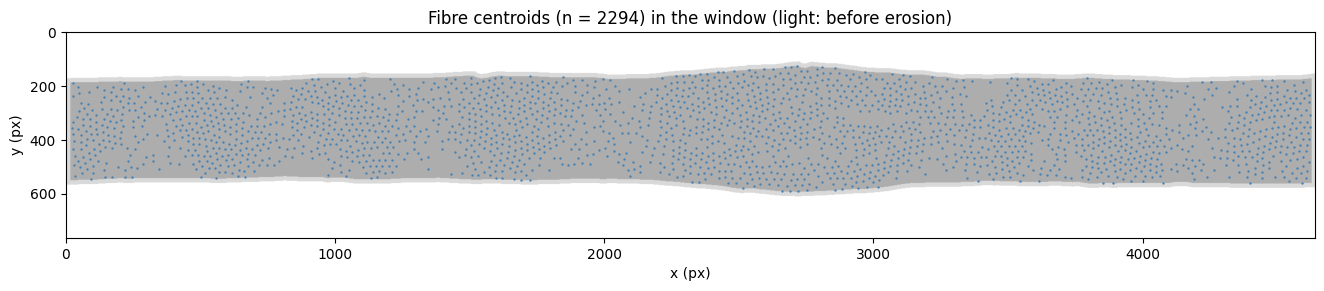

In [ ]:
fig, ax = plt.subplots(figsize=(18, 3))
ax.imshow(roi_win.mask, cmap="Greys", alpha=0.15, extent=(0, W * px_size, H * px_size, 0))
ax.imshow(np.ma.masked_where(~window.mask, window.mask), cmap="Greys", alpha=0.2, vmin=0, vmax=1,
          extent=(0, W * px_size, H * px_size, 0))
ax.scatter(*xy.T, s=0.5, color=COLOR)
ax.set_aspect("equal"); ax.set_xlabel(f"x ({px_unit})"); ax.set_ylabel(f"y ({px_unit})")
ax.set_title(f"Fibre centroids (n = {n}) in the window (light: before erosion)")
plt.tight_layout(); plt.show()

---
## 2. Intensity map

Gaussian kernel estimate λ(x) with σ = `KDE_SIGMA`, edge-corrected by the kernel mass inside the window.
For a homogeneous pattern λ(x)/λ ≈ 1 everywhere; bundles and resin pockets show up as deviations.
The empirical variance of log λ(x) is a (bandwidth-dependent) first look at the LGCP σ².

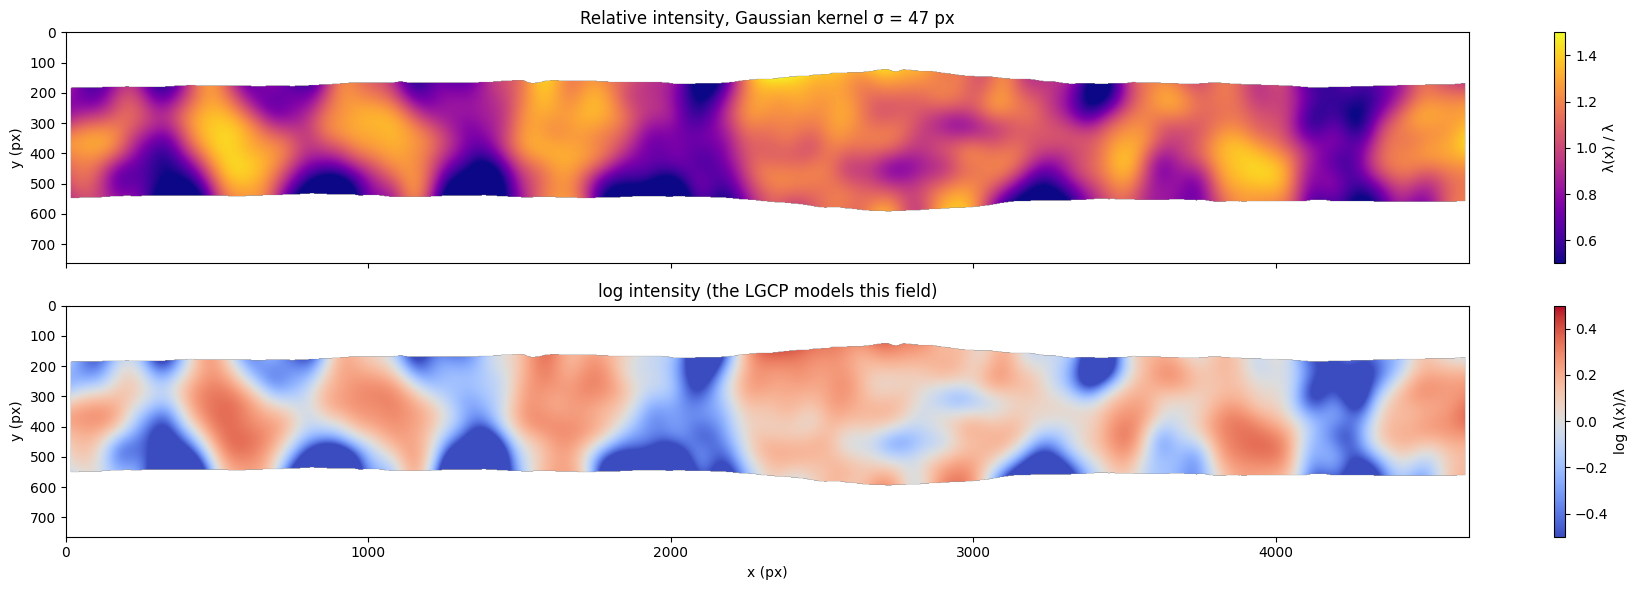

λ(x)/λ: 5–95 % range 0.56 – 1.32
Var(log λ(x)) at σ = 47 px: 0.0838  (smoothed → lower bound-ish for σ²)


In [ ]:
lam_map = kernel_intensity(xy, window, KDE_SIGMA)
rel     = lam_map / lam
log_rel = np.log(rel[window.mask])

fig, axes = plt.subplots(2, 1, figsize=(18, 6), sharex=True)
ext = (0, W * px_size, H * px_size, 0)
im = axes[0].imshow(rel, cmap="plasma", vmin=0.5, vmax=1.5, extent=ext)
fig.colorbar(im, ax=axes[0], label="λ(x) / λ", fraction=0.02)
axes[0].set_title(f"Relative intensity, Gaussian kernel σ = {KDE_SIGMA:.0f} {px_unit}")
im = axes[1].imshow(np.log(rel), cmap="coolwarm", vmin=-0.5, vmax=0.5, extent=ext)
fig.colorbar(im, ax=axes[1], label="log λ(x)/λ", fraction=0.02)
axes[1].set_title("log intensity (the LGCP models this field)")
axes[1].set_xlabel(f"x ({px_unit})")
for ax in axes:
    ax.set_ylabel(f"y ({px_unit})")
plt.tight_layout(); plt.show()

print(f"λ(x)/λ: 5–95 % range {np.nanpercentile(rel[window.mask], 5):.2f} – {np.nanpercentile(rel[window.mask], 95):.2f}")
print(f"Var(log λ(x)) at σ = {KDE_SIGMA:.0f} {px_unit}: {log_rel.var():.4f}  (smoothed → lower bound-ish for σ²)")

Intensity profile along the roving (x): points per window area in slices of `X_BIN`.  A smooth trend here
(instead of fluctuations around 1) means the pattern is *inhomogeneous* at the scale of the specimen — that also
shows up as g(r) > 1 at large r and inflates the LGCP σ² / ℓ.

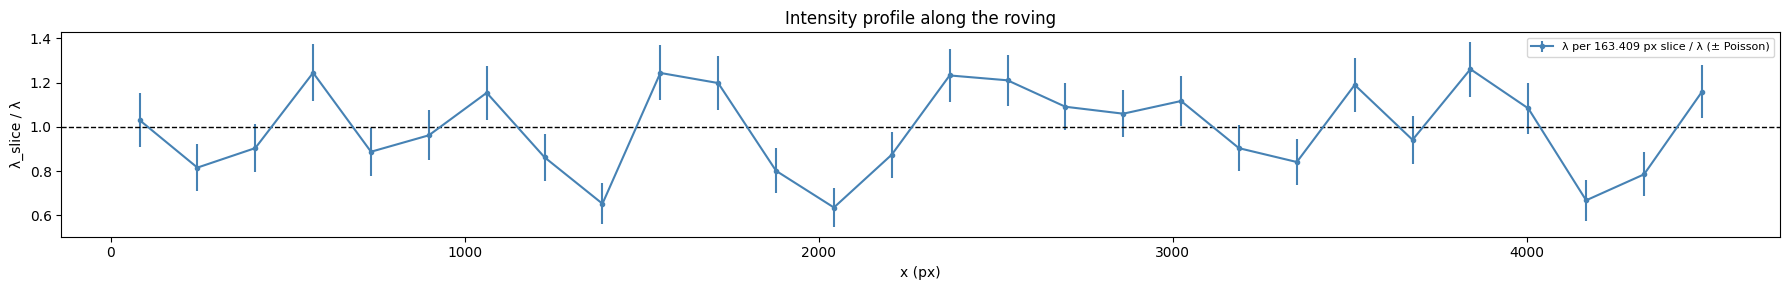

slice intensity: sd 0.191 (Poisson expectation 0.110), linear trend +0.008 per 1000 px


In [ ]:
edges = np.arange(0, W * px_size + X_BIN, X_BIN)
cnt   = np.histogram(xy[:, 0], edges)[0]
col_area = window.mask.sum(0) * window.pixel_size ** 2
area_bin = np.histogram((np.arange(window.shape[1]) + 0.5) * window.pixel_size, edges, weights=col_area)[0]
ok    = area_bin > 0.3 * np.median(area_bin[area_bin > 0])
xc    = 0.5 * (edges[1:] + edges[:-1])
prof  = cnt[ok] / area_bin[ok] / lam
err   = np.sqrt(cnt[ok]) / area_bin[ok] / lam           # Poisson error

fig, ax = plt.subplots(figsize=(18, 3))
ax.errorbar(xc[ok], prof, err, fmt="o-", ms=3, color=COLOR, label=f"λ per {X_BIN:g} {px_unit} slice / λ (± Poisson)")
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_xlabel(f"x ({px_unit})"); ax.set_ylabel("λ_slice / λ"); ax.legend(fontsize=8)
ax.set_title("Intensity profile along the roving")
plt.tight_layout(); plt.show()
print(f"slice intensity: sd {prof.std():.3f} (Poisson expectation {np.mean(err):.3f}), linear trend "
      f"{np.polyfit(xc[ok], prof, 1)[0] * 1000:+.3f} per 1000 {px_unit}")

---
## 3. Nearest-neighbour distances G(r)

Two null models, each `N_SIM` realisations with the same number of points in the same window:

* **CSR** — points uniformly in the window (binomial process); ignores that fibres cannot overlap
* **hard-core CSR (HC)** — the most random arrangement of *non-overlapping* fibres: homogeneous hard-core process
  with minimum distance d = `HC_D` · Ø (default one fibre diameter; `HC_POLY` → d_ij = `HC_D` · (r_i + r_j) with
  the measured radii), sampled by MCMC.  This is the relevant reference: deviations from HC are clustering
  (or extra order) *beyond* what non-overlapping alone implies.

Observed NN distances below d (smaller-than-median fibres touching, segmentation) lie outside the HC envelope
by construction; the share is printed below.  At very high packing (covered fraction λ·π·d²/4 ≳ 0.7) d is not
reachable with fixed n — the sampler then warns and stops at the largest reachable distance.

hard-core CSR: 39 realisations in 54 s, d = 23.34 px (= 1 Ø), covered fraction λπd²/4 = 0.550, smallest simulated NN = 1.000 Ø


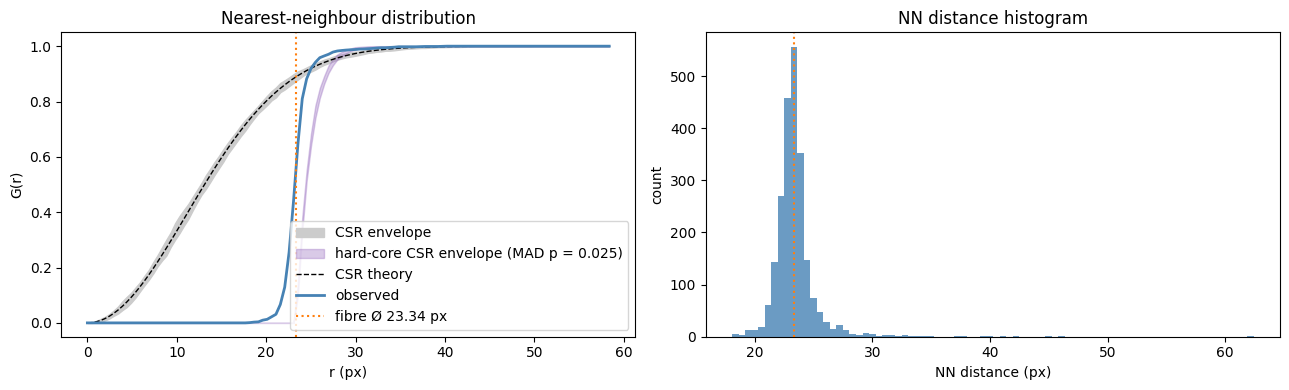

NN distance: min 18.09, 1 % 19.92, median 23.23 px  → median NN / Ø = 1.00
Clark–Evans R = mean NN / (0.5/√λ) = 1.68  (1 CSR, >1 regular, 2.15 hexagonal);  hard-core CSR: 1.79
observed NN distances below d = 23.34 px: 54.7%


In [ ]:
import time, warnings

csr = [window.sample_uniform(n, rng) for _ in range(N_SIM)]

t0 = time.time()
hc_d = HC_D * diam
with warnings.catch_warnings(record=True) as hc_warn:
    warnings.simplefilter("always")
    if HC_POLY:
        hc = [simulate_hardcore_cox(window, n, HC_D, n_sweeps=10, rng=rng, radii=rng.permutation(radii))
              for _ in range(N_SIM)]
    else:
        hc = [simulate_hardcore_cox(window, n, hc_d, n_sweeps=10, rng=rng) for _ in range(N_SIM)]
hc_min = min(nn_distances(p).min() for p in hc)
print(f"hard-core CSR: {N_SIM} realisations in {time.time() - t0:.0f} s, d = "
      + (f"{HC_D:g}·(r_i + r_j)" if HC_POLY else f"{hc_d:.2f} {px_unit} (= {HC_D:g} Ø)")
      + f", covered fraction λπd²/4 = {lam * np.pi * hc_d ** 2 / 4:.3f}, smallest simulated NN = {hc_min / diam:.3f} Ø")
if hc_warn:
    print(f"⚠ {len(hc_warn)}× {hc_warn[0].message}")

r_nn  = np.linspace(0, 2.5 * diam, 120)
G_obs = nn_function(xy, window, r_nn)
G_sim = np.array([nn_function(p, window, r_nn) for p in csr])
G_env = envelope(G_obs, G_sim)
G_hc  = np.array([nn_function(p, window, r_nn) for p in hc])
G_env_hc = envelope(G_obs, G_hc)
dnn   = nn_distances(xy)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.fill_between(r_nn, G_env["lo"], G_env["hi"], color="0.8", label="CSR envelope")
ax.fill_between(r_nn, G_env_hc["lo"], G_env_hc["hi"], color="tab:purple", alpha=0.35,
                label=f"hard-core CSR envelope (MAD p = {G_env_hc['p_mad']:.3f})")
ax.plot(r_nn, 1 - np.exp(-lam * np.pi * r_nn ** 2), "k--", lw=1, label="CSR theory")
ax.plot(r_nn, G_obs, color=COLOR, lw=2, label="observed")
ax.axvline(diam, color="tab:orange", ls=":", label=f"fibre Ø {diam:.2f} {px_unit}")
ax.set_xlabel(f"r ({px_unit})"); ax.set_ylabel("G(r)"); ax.legend(); ax.set_title("Nearest-neighbour distribution")
ax = axes[1]
ax.hist(dnn, bins=80, color=COLOR, alpha=0.8)
ax.axvline(diam, color="tab:orange", ls=":")
ax.set_xlabel(f"NN distance ({px_unit})"); ax.set_ylabel("count"); ax.set_title("NN distance histogram")
plt.tight_layout(); plt.show()

print(f"NN distance: min {dnn.min():.2f}, 1 % {np.percentile(dnn, 1):.2f}, median {np.median(dnn):.2f} {px_unit}"
      f"  → median NN / Ø = {np.median(dnn) / diam:.2f}")
print(f"Clark–Evans R = mean NN / (0.5/√λ) = {dnn.mean() / (0.5 / np.sqrt(lam)):.2f}  (1 CSR, >1 regular, 2.15 hexagonal)"
      f";  hard-core CSR: {np.mean([nn_distances(p).mean() for p in hc]) / (0.5 / np.sqrt(lam)):.2f}")
print(f"observed NN distances below d = {hc_d:.2f} {px_unit}: {np.mean(dnn < hc_d):.1%}")

---
## 4. Ripley's K, L(r) − r and pair correlation g(r) vs. CSR and hard-core CSR

* **L(r) − r** > 0 → more neighbours within r than CSR (clustering at scale r), < 0 → regularity
* **g(r)** = density of pairs at distance exactly r relative to CSR; the peaks are the neighbour shells of the
  packing, g > 1 at large r means clustering
* all scale parameters are multiples of the fibre diameter Ø (set in the first cell)
* **MAD test**: global Monte-Carlo test on L(r) − r over the given range; p = 1/(N_SIM + 1) = 0.025 is the
  smallest possible value (observed more extreme than all simulations)
* **vs. hard-core CSR**: L(r) − r or g(r) above the HC envelope at r ≥ a few Ø → clustering beyond the packing
  constraint; the test range starts at `R_MIN` (and at 1.5 Ø, after the contact distance)

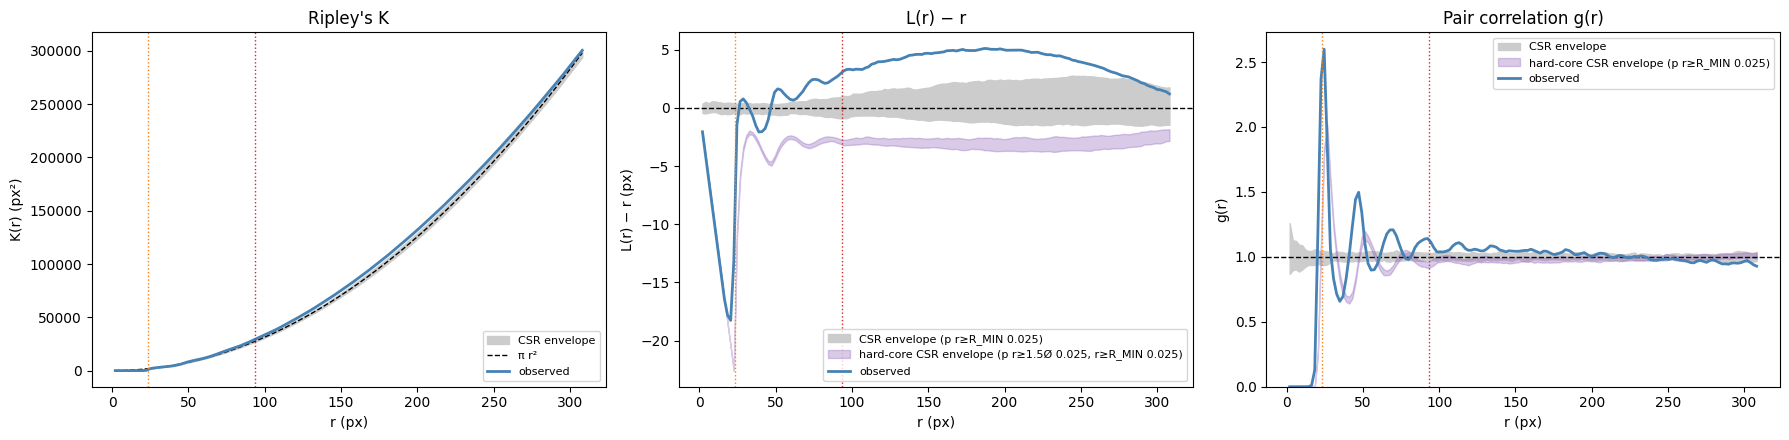

g(r) first peak at r = 24.64 px (= 1.06 Ø), height 2.60
max L(r) − r = +5.11 px at r = 186.9;  min -18.27 at r = 20.5
mean g(r) for r ≥ R_MIN = 93.4: 1.014  (1 = no long-range clustering)
MAD p vs CSR          : L all r 0.025, L r ≥ R_MIN 0.025, g r ≥ R_MIN 0.025
MAD p vs hard-core CSR: G 0.025, L r ≥ 1.5 Ø 0.025, L r ≥ R_MIN 0.025, g r ≥ R_MIN 0.025


In [ ]:
K_obs = k_function(xy, window, r)
g_obs = pair_correlation(xy, window, r)
L_obs = l_function(K_obs) - r

K_csr = np.array([k_function(p, window, r) for p in csr])
g_csr = np.array([pair_correlation(p, window, r) for p in csr])
L_csr = l_function(K_csr) - r

R_MIN = R_MIN_D * diam    # long-range part: beyond the neighbour shells of the packing
env_L_csr      = envelope(L_obs, L_csr)
env_g_csr      = envelope(g_obs, g_csr)
p_csr_all      = envelope(L_obs, L_csr, r, (0, R_MAX))["p_mad"]
p_csr_long     = envelope(L_obs, L_csr, r, (R_MIN, R_MAX))["p_mad"]
p_csr_long_g   = envelope(g_obs, g_csr, r, (R_MIN, R_MAX))["p_mad"]

K_hc = np.array([k_function(p, window, r) for p in hc])
g_hc = np.array([pair_correlation(p, window, r) for p in hc])
L_hc = l_function(K_hc) - r
env_L_hc     = envelope(L_obs, L_hc)
env_g_hc     = envelope(g_obs, g_hc)
p_hc_L_mid   = envelope(L_obs, L_hc, r, (1.5 * diam, R_MAX))["p_mad"]
p_hc_L_long  = envelope(L_obs, L_hc, r, (R_MIN, R_MAX))["p_mad"]
p_hc_g_long  = envelope(g_obs, g_hc, r, (R_MIN, R_MAX))["p_mad"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
ax = axes[0]
ax.fill_between(r, K_csr.min(0), K_csr.max(0), color="0.8", label="CSR envelope")
ax.plot(r, np.pi * r ** 2, "k--", lw=1, label="π r²")
ax.plot(r, K_obs, color=COLOR, lw=2, label="observed")
ax.set_title("Ripley's K"); ax.set_ylabel(f"K(r) ({px_unit}²)")
ax = axes[1]
ax.fill_between(r, env_L_csr["lo"], env_L_csr["hi"], color="0.8", label=f"CSR envelope (p r≥R_MIN {p_csr_long:.3f})")
ax.fill_between(r, env_L_hc["lo"], env_L_hc["hi"], color="tab:purple", alpha=0.35,
                label=f"hard-core CSR envelope (p r≥1.5Ø {p_hc_L_mid:.3f}, r≥R_MIN {p_hc_L_long:.3f})")
ax.axhline(0, color="k", ls="--", lw=1)
ax.plot(r, L_obs, color=COLOR, lw=2, label="observed")
ax.set_title("L(r) − r")
ax.set_ylabel(f"L(r) − r ({px_unit})")
ax = axes[2]
ax.fill_between(r, env_g_csr["lo"], env_g_csr["hi"], color="0.8", label="CSR envelope")
ax.fill_between(r, env_g_hc["lo"], env_g_hc["hi"], color="tab:purple", alpha=0.35,
                label=f"hard-core CSR envelope (p r≥R_MIN {p_hc_g_long:.3f})")
ax.axhline(1, color="k", ls="--", lw=1)
ax.plot(r, g_obs, color=COLOR, lw=2, label="observed")
ax.set_ylim(0, min(3.5, np.nanmax(g_obs) * 1.05))
ax.set_title("Pair correlation g(r)"); ax.set_ylabel("g(r)")
for ax in axes:
    ax.axvline(diam, color="tab:orange", ls=":", lw=1)
    ax.axvline(R_MIN, color="tab:red", ls=":", lw=1)
    ax.set_xlabel(f"r ({px_unit})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

short  = r <= 2 * diam
r_peak = r[short][np.nanargmax(g_obs[short])]
g_peak = np.nanmax(g_obs[short])
print(f"g(r) first peak at r = {r_peak:.2f} {px_unit} (= {r_peak / diam:.2f} Ø), height {g_peak:.2f}")
print(f"max L(r) − r = {L_obs.max():+.2f} {px_unit} at r = {r[np.argmax(L_obs)]:.1f};  min {L_obs.min():+.2f} at r = {r[np.argmin(L_obs)]:.1f}")
print(f"mean g(r) for r ≥ R_MIN = {R_MIN:.1f}: {np.nanmean(g_obs[r >= R_MIN]):.3f}  (1 = no long-range clustering)")
print(f"MAD p vs CSR          : L all r {p_csr_all:.3f}, L r ≥ R_MIN {p_csr_long:.3f}, g r ≥ R_MIN {p_csr_long_g:.3f}")
print(f"MAD p vs hard-core CSR: G {G_env_hc['p_mad']:.3f}, L r ≥ 1.5 Ø {p_hc_L_mid:.3f}, L r ≥ R_MIN {p_hc_L_long:.3f}, "
      f"g r ≥ R_MIN {p_hc_g_long:.3f}")

---
## 5. Directional K: along vs. across the roving

K restricted to pair orientations within ±20° of the x axis (along the roving) and of the y axis (across),
each rescaled to the isotropic K.  Different curves → anisotropic structure (e.g. fibre layers or elongated
resin pockets).

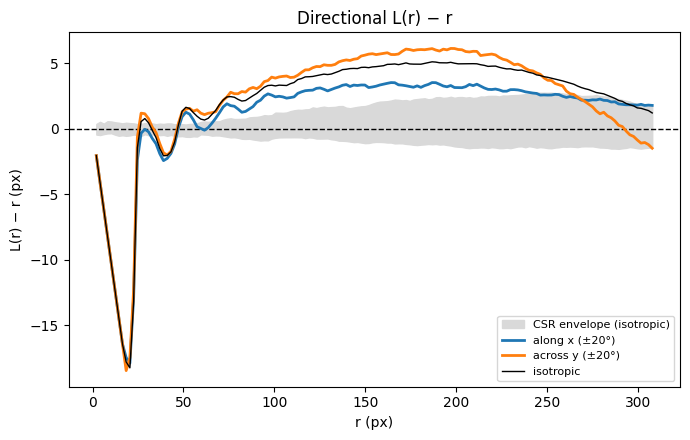

In [ ]:
SECTORS = {"along x (±20°)": (-20, 20), "across y (±20°)": (70, 110)}
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(0, color="k", ls="--", lw=1)
ax.fill_between(r, env_L_csr["lo"], env_L_csr["hi"], color="0.85", label="CSR envelope (isotropic)")
for (name, sec), c in zip(SECTORS.items(), ["tab:blue", "tab:orange"]):
    ax.plot(r, l_function(k_function(xy, window, r, sec)) - r, color=c, lw=2, label=name)
ax.plot(r, L_obs, color="k", lw=1, label="isotropic")
ax.set_xlabel(f"r ({px_unit})"); ax.set_ylabel(f"L(r) − r ({px_unit})"); ax.legend(fontsize=8)
ax.set_title("Directional L(r) − r")
plt.tight_layout(); plt.show()

---
## 6. LGCP fit by minimum contrast

Pair correlation of the LGCP: g(r) = exp(σ² ρ(r/ℓ)).  Fitted on r ∈ [`R_MIN`, `R_MAX`] (beyond the hard core)
to g (q = 1) and to K (q = 1/4, Diggle), with exponential and Gaussian covariance.  The K / exponential fit is
used for the simulations: the g fits only see the tail and can extrapolate a much too strong g below `R_MIN`.
The spread between the four fits shows how well σ² and ℓ are identified.

,sigma2,scale,model,stat,cost,at_bound,range_5pct
0,0.5162,54.4544,exponential,g,0.0433,False,163.3632
1,0.1400,131.6540,gaussian,g,0.0389,False,228.0315
2,0.1649,85.8251,exponential,K,0.0692,False,257.4753
3,0.0942,146.2119,gaussian,K,0.0490,False,253.2464


used fit: exponential on K
→ used: exponential, σ² = 0.1649, ℓ = 85.83 px  (log-intensity sd 0.406 → λ(x)/λ ≈ ×0.67 … ×1.50 at ±1 sd)


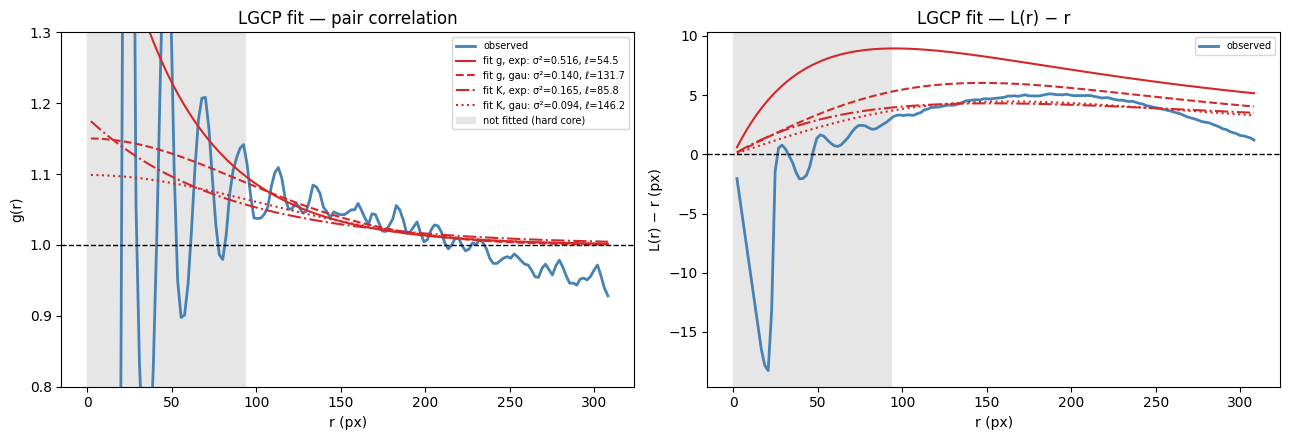

In [ ]:
fits = []
for stat, obs in [("g", g_obs), ("K", K_obs)]:
    for model in ["exponential", "gaussian"]:
        f = fit_lgcp_mincontrast(r, obs, stat=stat, r_range=(R_MIN, R_MAX), model=model, x0=(0.05, 0.5 * R_MAX))
        fits.append(f)
fit_df = pd.DataFrame(fits)
# practical range: distance where the field correlation has dropped to 5 %
fit_df["range_5pct"] = np.where(fit_df["model"] == "exponential", 3 * fit_df["scale"], np.sqrt(3) * fit_df["scale"])
display(fit_df.round(4))
if fit_df["at_bound"].any():
    print("⚠ some fits hit a parameter bound → ℓ not identifiable within R_MAX for those")

# preferred: exponential fitted to K (Diggle; the g fits extrapolate poorly below R_MIN);
# if it hits a bound, the first other fit that converged inside the bounds
pref = [f for f in fits if (f["stat"], f["model"]) == ("K", "exponential")] + fits
best = next((f for f in pref if not f["at_bound"]), pref[0])
print(f"used fit: {best['model']} on {best['stat']}")
SIGMA2, ELL, MODEL = best["sigma2"], best["scale"], best["model"]
print(f"→ used: {MODEL}, σ² = {SIGMA2:.4f}, ℓ = {ELL:.2f} {px_unit}  "
      f"(log-intensity sd {np.sqrt(SIGMA2):.3f} → λ(x)/λ ≈ ×{np.exp(-np.sqrt(SIGMA2)):.2f} … ×{np.exp(np.sqrt(SIGMA2)):.2f} at ±1 sd)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(r, g_obs, color=COLOR, lw=2, label="observed")
for f, ls in zip(fits, ["-", "--", "-.", ":"]):
    ax.plot(r, lgcp_pcf(r, f["sigma2"], f["scale"], f["model"]), ls=ls, color="tab:red",
            label=f"fit {f['stat']}, {f['model'][:3]}: σ²={f['sigma2']:.3f}, ℓ={f['scale']:.1f}")
ax.axhline(1, color="k", lw=1, ls="--"); ax.axvspan(0, R_MIN, color="0.9", label="not fitted (hard core)")
g_long = g_obs[r >= R_MIN]
ax.set_ylim(min(0.8, np.nanmin(g_long) - 0.05), max(1.3, np.nanmax(g_long) + 0.1)); ax.set_ylabel("g(r)"); ax.set_title("LGCP fit — pair correlation")
ax = axes[1]
ax.plot(r, L_obs, color=COLOR, lw=2, label="observed")
for f, ls in zip(fits, ["-", "--", "-.", ":"]):
    ax.plot(r, l_function(lgcp_k(r, f["sigma2"], f["scale"], f["model"])) - r, ls=ls, color="tab:red")
ax.axhline(0, color="k", lw=1, ls="--"); ax.axvspan(0, R_MIN, color="0.9")
ax.set_ylabel(f"L(r) − r ({px_unit})"); ax.set_title("LGCP fit — L(r) − r")
for ax in axes:
    ax.set_xlabel(f"r ({px_unit})"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

---
## 7. LGCP goodness of fit

`N_SIM` realisations of the fitted LGCP (mean intensity λ, Gaussian field on a `SIM_DOWN` grid) in the same
window.  The MAD test is evaluated on r ≥ `R_MIN` only — at short range the LGCP has no hard core and is
rejected by construction.

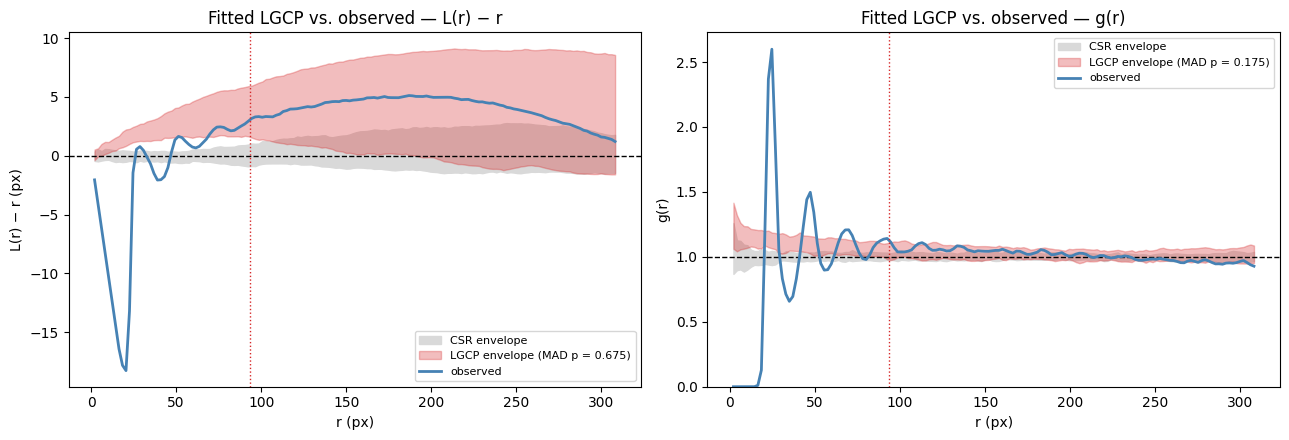

points per LGCP realisation: 2278 ± 124  (observed 2294)


In [ ]:
win_sim = MaskWindow.from_mask(roi_mask, px_size, down=SIM_DOWN).eroded(WIN_ERODE)
lgcp_pts = [simulate_lgcp(win_sim, lam, SIGMA2, ELL, MODEL, rng) for _ in range(N_SIM)]
lgcp_pts = [p[window.contains(p)] for p in lgcp_pts]                      # same window as the data

K_lg = np.array([k_function(p, window, r) for p in lgcp_pts])
g_lg = np.array([pair_correlation(p, window, r) for p in lgcp_pts])
L_lg = l_function(K_lg) - r
env_L_lg = envelope(L_obs, L_lg, r, (R_MIN, R_MAX))
env_g_lg = envelope(g_obs, g_lg, r, (R_MIN, R_MAX))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, obs, el, ec, ref, lab in [
    (axes[0], L_obs, env_L_lg, env_L_csr, 0, f"L(r) − r ({px_unit})"),
    (axes[1], g_obs, env_g_lg, env_g_csr, 1, "g(r)"),
]:
    ax.fill_between(r, ec["lo"], ec["hi"], color="0.85", label="CSR envelope")
    ax.fill_between(r, el["lo"], el["hi"], color="tab:red", alpha=0.3, label=f"LGCP envelope (MAD p = {el['p_mad']:.3f})")
    ax.axhline(ref, color="k", ls="--", lw=1)
    ax.plot(r, obs, color=COLOR, lw=2, label="observed")
    ax.axvline(R_MIN, color="tab:red", ls=":", lw=1)
    ax.set_xlabel(f"r ({px_unit})"); ax.set_ylabel(lab); ax.legend(fontsize=8)
axes[1].set_ylim(0, min(3.5, np.nanmax(g_obs) * 1.05))
axes[0].set_title("Fitted LGCP vs. observed — L(r) − r"); axes[1].set_title("Fitted LGCP vs. observed — g(r)")
plt.tight_layout(); plt.show()

print(f"points per LGCP realisation: {np.mean([len(p) for p in lgcp_pts]):.0f} ± {np.std([len(p) for p in lgcp_pts]):.0f}  (observed {n})")

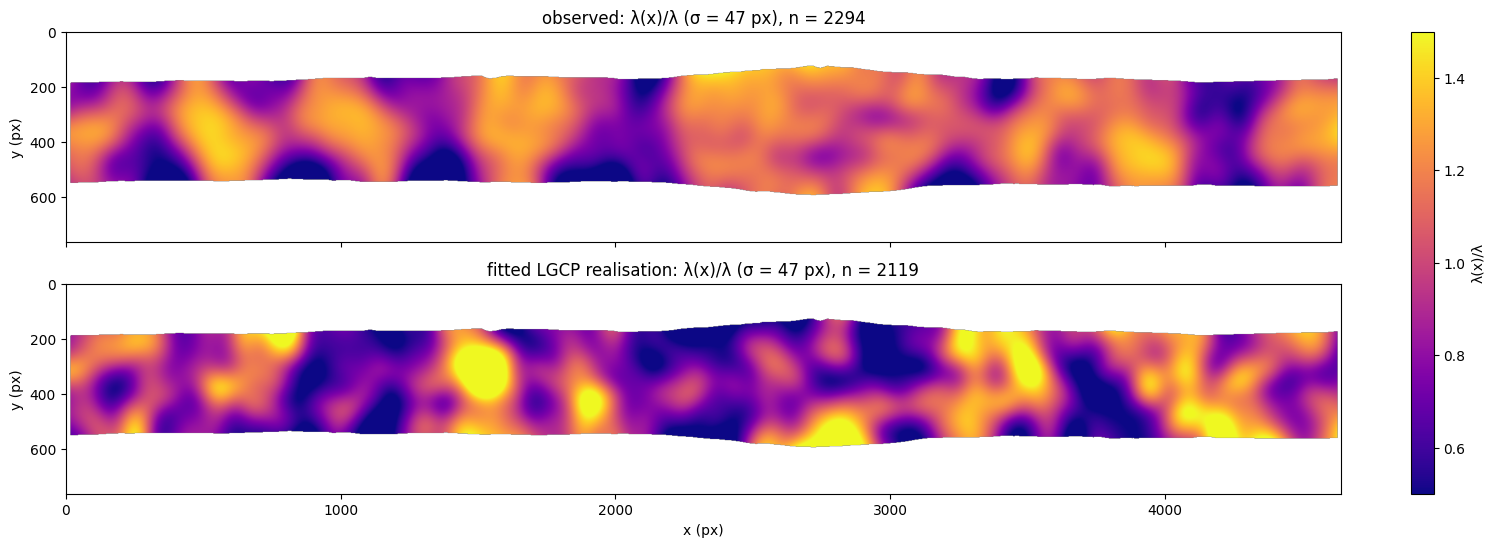

In [ ]:
# one realisation next to the data: intensity maps at the same bandwidth
fig, axes = plt.subplots(2, 1, figsize=(18, 6), sharex=True)
for ax, pts, title in [(axes[0], xy, "observed"), (axes[1], lgcp_pts[0], "fitted LGCP realisation")]:
    im = ax.imshow(kernel_intensity(pts, window, KDE_SIGMA) / lam, cmap="plasma", vmin=0.5, vmax=1.5, extent=ext)
    ax.set_title(f"{title}: λ(x)/λ (σ = {KDE_SIGMA:.0f} {px_unit}), n = {len(pts)}"); ax.set_ylabel(f"y ({px_unit})")
fig.colorbar(im, ax=axes, fraction=0.02, label="λ(x)/λ")
axes[1].set_xlabel(f"x ({px_unit})")
plt.show()

---
## 7b. Bundle model: hard-core fibres in the excursion set of a Gaussian field

Why the LGCP fits only moderately: the data are *two-phase* — densely packed bundles (fibres touching, g ≈ 2.5 at
1 Ø) and nearly empty resin pockets — while an LGCP has smooth intensity and no hard core.

**Model.**  Z = stationary Gaussian field (covariance `BUNDLE_COV`, scale ℓ).  Bundles = the area fraction p_b of
the window with the largest Z (excursion set {Z > u}, i.e. a clipped LGCP field).  All n fibres are placed
in the bundles as a *polydisperse* hard-core process: the measured fibre radii, neighbours at least
c · (r_i + r_j) apart (contact factor c = `CONTACT_Q` % percentile of the observed NN distance / (r_i + r_j)),
sampled by MCMC with growing disks.  p_b = 1 → homogeneous packing (no clustering).

**Surface layer** (`SKIN`).  Tapes / rovings often have a resin-rich surface layer (section 1b).  A stationary
model cannot produce it, and it raises L(r) − r (pairs concentrated in the core) without showing in the central
quadrats.  With `SKIN` the bundle *coverage* follows the measured intensity profile ρ(b) vs. depth b below the
surface: P(bundle | x) = p_b · ρ(b(x)) (no extra fitted parameter; ρ is estimated from the data).

**Fit.**  No closed form for K → simulation-based minimum contrast on L(r) − r over *all* r (the hard core is
part of the model) **and** on log D(a) (count variance, section 8), each block scaled by its spread under CSR:
coarse grid (ℓ, p_b), then a finer grid around the best point.  The goodness of fit is then tested over all r.
Runtime: a few minutes (pure-Python MCMC).

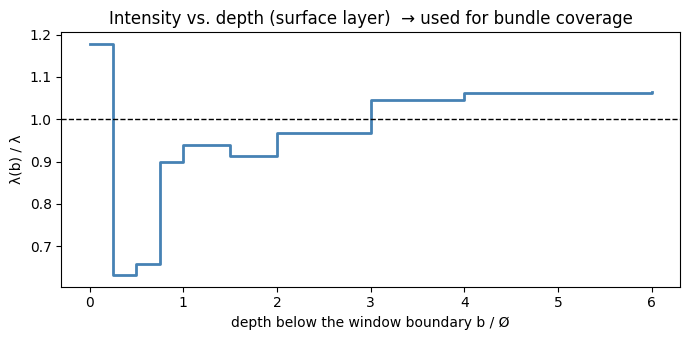

fit: 306 s   contact factor c = 0.946  (min. distance c·(r_i + r_j))
→ bundle model: ℓ = 140.1 px (= 6.00 Ø), bundle area fraction p_b = 0.80, local packing in bundles λ_b = λ / p_b = 0.00161 /px² (×1.25)


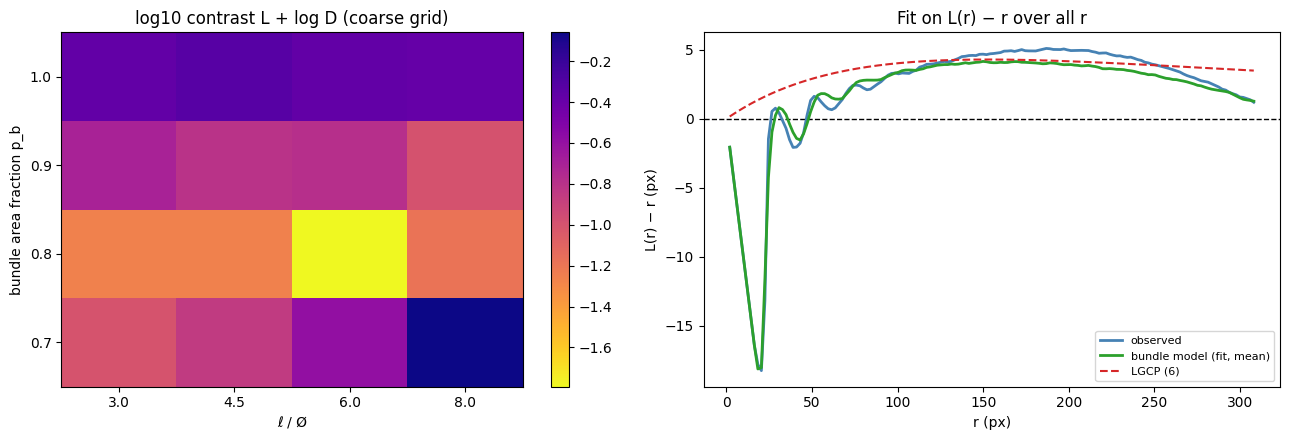

In [ ]:
import time, warnings

from scipy.spatial import cKDTree
_, nn_idx = cKDTree(xy).query(xy, k=2)
contact   = np.percentile(dnn / (radii + radii[nn_idx[:, 1]]), CONTACT_Q)
win_b     = MaskWindow.from_mask(roi_mask, px_size, down=SIM_DOWN).eroded(WIN_ERODE)   # field grid

# depth profile of the intensity → bundle coverage factor on the field grid
b_cent, rho_b = boundary_profile(xy, window, np.array(SKIN_EDGES_D) * diam)
if SKIN:
    win_b.boundary_distance(xy[:1])
    depth_b = win_b._bdist[win_b.mask]
    rho_grid = rho_b[np.clip(np.digitize(depth_b, np.array(SKIN_EDGES_D) * diam) - 1, 0, len(rho_b) - 1)]
    rho_grid = rho_grid / np.average(rho_grid)                          # mean coverage stays p_b
else:
    rho_grid = None
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.step(np.array(SKIN_EDGES_D[:-1]) , rho_b, where="post", color=COLOR, lw=2)
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_xlabel("depth below the window boundary b / Ø"); ax.set_ylabel("λ(b) / λ")
ax.set_title("Intensity vs. depth (surface layer)" + ("  → used for bundle coverage" if SKIN else ""))
plt.tight_layout(); plt.show()

# contrast: L(r) − r and log D(a), each block weighted by 1 / (length · CSR variance)
D_fit, nq_fit = quadrat_dispersion(xy, window, A_SIZES)
a_fit = A_SIZES[nq_fit >= 5]
D_csr_fit = np.array([quadrat_dispersion(p, window, a_fit)[0] for p in csr])
obs_vec = np.concatenate([L_obs, np.log(D_fit[nq_fit >= 5])])
w_vec   = np.concatenate([np.full(len(r), 1 / (len(r) * np.nanmean(np.var(L_csr, 0)))),
                          1 / (len(a_fit) * np.var(np.log(D_csr_fit), 0))])


def simulate_bundles(prm, rng, n_sweeps=5, return_field=False, return_radii=False):
    f = gaussian_random_field(win_b.shape, win_b.pixel_size, 1.0, prm["ell"], BUNDLE_COV, rng)
    z = np.full(win_b.shape, -np.inf)
    p_b = prm["p_b"] if rho_grid is None else np.clip(prm["p_b"] * rho_grid, 0, 1)
    z[win_b.mask] = excursion_log_field(f[win_b.mask], p_b)[0]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")          # "hard core grew only to …" at very dense bundles
        rad = rng.permutation(radii)               # pts[k] has radius rad[k]
        pts = simulate_hardcore_cox(window, n, contact, z, win_b.pixel_size, n_sweeps=n_sweeps, rng=rng, radii=rad)
    out = (pts,) + ((z,) if return_field else ()) + ((rad,) if return_radii else ())
    return out[0] if len(out) == 1 else out


def summary_LD(pts):
    with np.errstate(divide="ignore"):
        return np.concatenate([l_function(k_function(pts, window, r)) - r,
                               np.log(quadrat_dispersion(pts, window, a_fit)[0])])


t0 = time.time()
coarse = fit_by_simulation(simulate_bundles, summary_LD, obs_vec,
                           [{"ell": e * diam, "p_b": pb} for e in GRID_ELL_D for pb in GRID_PB],
                           n_rep=FIT_REP, weights=w_vec, rng=rng)
b0 = coarse[0]
fine_ell = b0["ell"] * np.array([0.8, 1.0, 1.2])
fine_pb  = np.clip(b0["p_b"] + np.array([-0.05, 0.0, 0.05]), 0.3, 1.0)
fine = fit_by_simulation(simulate_bundles, summary_LD, obs_vec,
                         [{"ell": e, "p_b": pb} for e in fine_ell for pb in np.unique(fine_pb)],
                         n_rep=FIT_REP + 1, weights=w_vec, rng=rng)
bfit = min(coarse[:1] + fine, key=lambda o: o["cost"])
print(f"fit: {time.time() - t0:.0f} s   contact factor c = {contact:.3f}  (min. distance c·(r_i + r_j))")
print(f"→ bundle model: ℓ = {bfit['ell']:.1f} {px_unit} (= {bfit['ell'] / diam:.2f} Ø), bundle area fraction "
      f"p_b = {bfit['p_b']:.2f}, local packing in bundles λ_b = λ / p_b = {lam / bfit['p_b']:.5f} /{px_unit}² "
      f"(×{1 / bfit['p_b']:.2f})")

cost_map = pd.DataFrame([{k: o[k] for k in ("ell", "p_b", "cost")} for o in coarse])
cost_map["ell / Ø"] = (cost_map["ell"] / diam).round(1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cm = cost_map.pivot(index="p_b", columns="ell / Ø", values="cost")
im = axes[0].imshow(np.log10(cm.values), origin="lower", cmap="plasma_r", aspect="auto")
axes[0].set_xticks(range(cm.shape[1]), cm.columns); axes[0].set_yticks(range(cm.shape[0]), cm.index)
axes[0].set_xlabel("ℓ / Ø"); axes[0].set_ylabel("bundle area fraction p_b")
axes[0].set_title("log10 contrast L + log D (coarse grid)"); fig.colorbar(im, ax=axes[0])
ax = axes[1]
ax.axhline(0, color="k", ls="--", lw=1)
ax.plot(r, L_obs, color=COLOR, lw=2, label="observed")
ax.plot(r, bfit["summary"][:len(r)], color="tab:green", lw=2, label="bundle model (fit, mean)")
ax.plot(r, l_function(lgcp_k(r, SIGMA2, ELL, MODEL)) - r, color="tab:red", ls="--", label="LGCP (6)")
ax.set_xlabel(f"r ({px_unit})"); ax.set_ylabel(f"L(r) − r ({px_unit})"); ax.legend(fontsize=8)
ax.set_title("Fit on L(r) − r over all r")
plt.tight_layout(); plt.show()

In [ ]:
t0 = time.time()
res_b = [simulate_bundles(bfit, rng, n_sweeps=10, return_field=(k == 0), return_radii=True) for k in range(N_SIM_B)]
bund_field = res_b[0][1]
bund       = [o[0] for o in res_b]
bund_rad   = [o[-1] for o in res_b]
K_b = np.array([k_function(p, window, r) for p in bund])
g_b = np.array([pair_correlation(p, window, r) for p in bund])
L_b = l_function(K_b) - r
env_L_b     = envelope(L_obs, L_b, r, (0, R_MAX))
env_g_b     = envelope(g_obs, g_b, r, (0.5 * diam, R_MAX))
env_L_b_lng = envelope(L_obs, L_b, r, (R_MIN, R_MAX))
env_g_b_lng = envelope(g_obs, g_b, r, (R_MIN, R_MAX))
G_b = np.array([nn_function(p, window, r_nn) for p in bund])
env_G_b = envelope(G_obs, G_b)
print(f"{N_SIM_B} realisations: {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
ax = axes[0]
ax.fill_between(r, env_L_lg["lo"], env_L_lg["hi"], color="tab:red", alpha=0.2, label="LGCP envelope")
ax.fill_between(r, env_L_b["lo"], env_L_b["hi"], color="tab:green", alpha=0.35,
                label=f"bundle envelope (MAD p all r = {env_L_b['p_mad']:.2f})")
ax.axhline(0, color="k", ls="--", lw=1)
ax.plot(r, L_obs, color=COLOR, lw=2, label="observed"); ax.set_ylabel(f"L(r) − r ({px_unit})")
ax.set_title("L(r) − r")
ax = axes[1]
ax.fill_between(r, env_g_lg["lo"], env_g_lg["hi"], color="tab:red", alpha=0.2, label="LGCP envelope")
ax.fill_between(r, env_g_b["lo"], env_g_b["hi"], color="tab:green", alpha=0.35,
                label=f"bundle envelope (MAD p r ≥ Ø/2 = {env_g_b['p_mad']:.2f})")
ax.axhline(1, color="k", ls="--", lw=1)
ax.plot(r, g_obs, color=COLOR, lw=2, label="observed"); ax.set_ylabel("g(r)")
ax.set_ylim(0, min(3.5, np.nanmax(g_obs) * 1.1)); ax.set_title("g(r)")
ax = axes[2]
ax.fill_between(r_nn, env_G_b["lo"], env_G_b["hi"], color="tab:green", alpha=0.35, label="bundle envelope")
ax.plot(r_nn, G_obs, color=COLOR, lw=2, label="observed"); ax.set_ylabel("G(r)")
ax.set_title("Nearest-neighbour G(r)")
for ax in axes:
    ax.axvline(R_MIN, color="tab:red", ls=":", lw=1)
    ax.set_xlabel(f"r ({px_unit})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

KeyboardInterrupt: 

In [ ]:
# one realisation: bundles (excursion set) and points, next to the observed pattern
fig, axes = plt.subplots(2, 1, figsize=(18, 6), sharex=True)
axes[0].imshow(roi_win.mask, cmap="Greys", alpha=0.15, extent=ext)
axes[0].scatter(*xy.T, s=1, color=COLOR); axes[0].set_title(f"observed, n = {n}")
bext = (0, win_b.shape[1] * win_b.pixel_size, win_b.shape[0] * win_b.pixel_size, 0)
axes[1].imshow(np.where(win_b.mask, np.isfinite(bund_field), np.nan), cmap="Greens", vmin=0, vmax=2.5, extent=bext)
axes[1].scatter(*bund[0].T, s=1, color="k")
axes[1].set_title(f"bundle model realisation (green: bundles, p_b = {bfit['p_b']:.2f}, ℓ = {bfit['ell']:.0f} {px_unit})")
for ax in axes:
    ax.set_aspect("equal"); ax.set_ylabel(f"y ({px_unit})")
axes[1].set_xlabel(f"x ({px_unit})")
plt.tight_layout(); plt.show()

---
## 8. Quadrat dispersion

Index of dispersion D(a) = Var(N)/E(N) of the counts in square quadrats of side a (only quadrats fully inside
the ROI).  CSR → 1; the hard core pushes D below 1 (counts more even than Poisson); clustering makes D grow
with a.  Compared with the CSR, LGCP and bundle-model simulations from above (not used in any fit → an
independent check).

In [ ]:
D_obs, nq = quadrat_dispersion(xy, window, A_SIZES)
use = nq >= 5                                            # sizes with enough quadrats fully inside
A_SIZES, A_SIZES_D, D_obs, nq = A_SIZES[use], A_SIZES_D[use], D_obs[use], nq[use]
D_csr = np.array([quadrat_dispersion(p, window, A_SIZES)[0] for p in csr])
D_lg  = np.array([quadrat_dispersion(p, window, A_SIZES)[0] for p in lgcp_pts])
D_b   = np.array([quadrat_dispersion(p, window, A_SIZES)[0] for p in bund])
D_hc  = np.array([quadrat_dispersion(p, window, A_SIZES)[0] for p in hc])

fig, ax = plt.subplots(figsize=(7, 4.5))
for D, c, lab in [(D_csr, "0.6", "CSR"), (D_hc, "tab:purple", "hard-core CSR"), (D_lg, "tab:red", "fitted LGCP"),
                  (D_b, "tab:green", "bundle model")]:
    lo, hi = np.nanquantile(D, [0.025, 0.975], axis=0)
    ax.fill_between(A_SIZES, lo, hi, color=c, alpha=0.3, label=f"{lab} envelope")
ax.plot(A_SIZES, D_obs, "o-", color=COLOR, lw=2, label="observed")
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xticks(A_SIZES, [f"{a:.0f}" for a in A_SIZES])
ax.set_xlabel(f"quadrat side a ({px_unit})"); ax.set_ylabel("Var(N) / E(N)"); ax.legend(fontsize=8)
ax.set_title("Index of dispersion vs. quadrat size")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"a": A_SIZES, "a / Ø": A_SIZES_D, "quadrats": nq, "E(N)": lam * A_SIZES ** 2, "D obs": D_obs,
                      "D CSR": np.nanmean(D_csr, 0), "D HC": np.nanmean(D_hc, 0), "D LGCP": np.nanmean(D_lg, 0),
                      "D bundle": np.nanmean(D_b, 0)}).round(3))

---
## 9. Two-point correlation of the fibre phase: S2, C2 and integral range

Phase statistics of the binarised fibre map (instead of the fibre centres), on the same window:

* **S2(h)** = P(x and x + h both in fibre), window-corrected (no periodic wrap, background / outside excluded);
  S2(0) = φ, S2(∞) = φ²
* **C2(h) = S2(h) − φ²** (auto-covariance), C2(0) = φ(1 − φ), C2 → 0.  C2 < 0 at about one Ø = the matrix gap
  around each fibre (regular packing); C2 > 0 at larger h = clustering
* **Link to the centres.**  For non-overlapping disks C2 = λ γ̄_D + λ² (g − 1) ∗ γ̄_D (γ̄_D = disk set covariance),
  so the point-pattern level (λ, g; for an LGCP g = exp(k)) fixes C2 — computed from the measured g as a check
* **Integral range** A = ∫ C2 dh / (φ(1 − φ)) (unclamped: the negative lobe counts).  It sets the local-V_f
  variance in large boxes, Var[φ_B] ≈ φ(1 − φ) A / |B|, the number of independent units n_eff = |W| / A, and
  the box size for a target sd of the local V_f — the rigorous form of n_eff ≈ |W| / ℓ²
* **Box variance** measured directly vs. predicted exactly from C2, and for the hard-core and bundle-model
  realisations rendered as disks with the measured radii — C2 and the box variance are not used in any fit,
  so they validate the generators

In [ ]:
import cv2

SD_PHI_TARGET = 0.01      # target sd of the local fibre fraction (absolute) for the box / RVE size
N_RENDER      = 5         # model realisations rendered as disks

with h5py.File(h5_path, "r") as hf:
    fib = hf["label_map" if "label_map" in hf else "labels"][()] > 0
hw, ww = window.shape
phase = cv2.resize(fib.astype(np.float32), (ww, hw), interpolation=cv2.INTER_AREA) if WIN_DOWN > 1 \
    else fib[:hw, :ww].astype(np.float32)
del fib
ps  = window.pixel_size
R2  = int(R_MAX / ps)
r2  = np.arange(1, R2 + 1) * ps

S2, phi_f, pairs2 = s2_window(phase, window.mask, R2)
C2   = S2 - phi_f ** 2
c2_r = radial_profile(C2, ps, r2, weights=pairs2)
c2_x = radial_profile(C2, ps, r2, (-20, 20), weights=pairs2)
c2_y = radial_profile(C2, ps, r2, (70, 110), weights=pairs2)
c2_g = c2_from_pcf(r, g_obs, lam, radii, ps, R2)                  # from the centres' g(r)
phi_g = lam * np.mean(np.pi * radii ** 2)
c2_g_r = radial_profile(c2_g, ps, r2)
nrm  = phi_f * (1 - phi_f)

zero = np.nonzero(c2_r <= 0)[0]
r_c2_zero = r2[zero[0]] if len(zero) else np.nan
A_r = integral_range(C2, phi_f, ps, r2)
A_clamped = integral_range(np.clip(C2, 0, None), phi_f, ps, r2)     # as in descriptors.integral_range_from_S2r
# A(R) converged if it varies < 20 % over the outer half of R; otherwise the window is too small (e.g. tape
# thickness) for the correlation range → A is only indicative (maximum of A(R))
outer = r2 >= 0.5 * R_MAX
A_conv = bool(np.ptp(A_r[outer]) < 0.2 * np.abs(np.median(A_r[outer])))
A_int = float(np.median(A_r[outer])) if A_conv else float(A_r.max())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
ax = axes[0]
ax.plot(np.r_[0, r2], np.r_[S2[R2, R2], radial_profile(S2, ps, r2, weights=pairs2)], color=COLOR, lw=2, label="S2(r)")
ax.axhline(phi_f, color="k", ls=":", lw=1, label=f"φ = {phi_f:.3f}")
ax.axhline(phi_f ** 2, color="k", ls="--", lw=1, label=f"φ² = {phi_f ** 2:.3f}")
ax.set_ylabel("S2(r)"); ax.set_title("Two-point probability")
ax = axes[1]
ax.axhline(0, color="k", ls="--", lw=1)
ax.plot(r2, c2_r / nrm, color=COLOR, lw=2, label="C2 / φ(1−φ), isotropic")
ax.plot(r2, c2_x / nrm, color="tab:blue", lw=1, alpha=0.7, label="along x (±20°)")
ax.plot(r2, c2_y / nrm, color="tab:orange", lw=1, alpha=0.7, label="across y (±20°)")
ax.plot(r2, c2_g_r / (phi_g * (1 - phi_g)), color="tab:red", ls="--", lw=1.5, label="from centres: λγ̄ + λ²(g−1)∗γ̄")
ax.set_ylim(-0.3, 0.5); ax.set_ylabel("C2(r) / φ(1−φ)"); ax.set_title("Normalised auto-covariance")
ax = axes[2]
ax.plot(r2, A_r, color=COLOR, lw=2, label="A(R), unclamped")
ax.plot(r2, A_clamped, color="0.5", ls="--", label="A(R) with C2 clamped ≥ 0 (biased)")
ax.axhline(A_int, color="tab:green", ls=":",
           label=(f"plateau A = {A_int:.0f}" if A_conv else f"not converged, max A = {A_int:.0f}") + f" {px_unit}²")
ax.set_ylabel(f"A(R) ({px_unit}²)"); ax.set_title("Cumulative integral range")
for ax in axes:
    ax.axvline(diam, color="tab:orange", ls=":", lw=1)
    ax.set_xlabel(f"r ({px_unit})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"φ (phase, window) = {phi_f:.4f};  λ·mean(πr²) from the centres = {phi_g:.4f}")
print(f"C2 first zero crossing at r = {r_c2_zero:.2f} {px_unit} (= {r_c2_zero / diam:.2f} Ø)")
print(f"integral range A = {A_int:.0f} {px_unit}² (√A = {np.sqrt(A_int):.1f} {px_unit} = {np.sqrt(A_int) / diam:.2f} Ø)"
      + ("" if A_conv else "  ⚠ A(R) not converged within R_MAX (window too thin) → indicative only")
      + f";  clamped C2 ≥ 0 would give {A_clamped[outer].max():.0f}")
print(f"n_eff = |W| / A = {window.area / A_int:.0f}   (LGCP: |W| / ℓ² = {window.area / ELL ** 2:.0f})")

In [ ]:
# local fibre-fraction variance vs. box size: measured, exact from C2, asymptotic, and rendered model realisations
box_px = np.unique(np.round(np.geomspace(1.0 * diam, R_MAX, 9) / ps).astype(int))
box    = box_px * ps
v_obs, nb_obs, _ = box_fraction_variance(phase, window.mask, box_px)
v_c2   = box_variance_from_c2(C2, box_px)
v_asym = np.where(box >= 2 * np.sqrt(A_int), phi_f * (1 - phi_f) * A_int / box ** 2, np.nan)   # large-box asymptote


def model_box_var(pt_sets, rad_sets):
    out = []
    for p, rd in zip(pt_sets[:N_RENDER], rad_sets[:N_RENDER]):
        img = render_disks(p, rd, window.shape, ps, down=2)
        out.append(box_fraction_variance(img, window.mask, box_px)[0])
    return np.array(out)


t0 = time.time()
v_hc = model_box_var(hc, [rng.permutation(radii) for _ in range(N_RENDER)])
v_bd = model_box_var(bund, bund_rad)
print(f"rendering + box variances: {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(box, v_obs, "o-", color=COLOR, lw=2, label="observed (measured)")
ax.plot(box, v_c2, "s--", color="k", ms=4, label="observed, exact from C2")
ax.plot(box, v_asym, ":", color="tab:green", label="φ(1−φ) A / |B|")
for v, c, lab in [(v_hc, "tab:purple", "hard-core CSR (rendered)"), (v_bd, "tab:green", "bundle model (rendered)")]:
    ax.fill_between(box, np.nanmin(v, 0), np.nanmax(v, 0), color=c, alpha=0.3, label=lab)
ax.axhline(SD_PHI_TARGET ** 2, color="tab:red", ls="--", lw=1, label=f"sd(φ_B) = {SD_PHI_TARGET:g}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(f"box side a ({px_unit})"); ax.set_ylabel("Var[φ_B]"); ax.legend(fontsize=8)
ax.set_title("Variance of the local fibre fraction")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"a": box, "a / Ø": box / diam, "boxes": nb_obs, "sd obs": np.sqrt(v_obs),
                      "sd from C2": np.sqrt(v_c2), "sd HC": np.sqrt(np.nanmean(v_hc, 0)),
                      "sd bundle": np.sqrt(np.nanmean(v_bd, 0))}).round(4))
print("note: 'measured' uses only boxes fully inside the window (core); 'from C2' covers the whole window incl. the "
      "surface layer → a gap between both indicates through-thickness inhomogeneity")

**Inspection unit of a tape: full-thickness strips.**  A tape is thinner than its correlation range, so square
boxes never reach the asymptotic regime.  The relevant unit for incoming inspection is a strip over the full
thickness of length L along the tape: φ per strip, its sd vs. L, and the strip length needed for
sd(φ_strip) = `SD_PHI_TARGET` from the large-L scaling Var ∝ 1/L (Var · L → const.).

In [ ]:
col_f = (phase * window.mask).sum(0)
col_a = window.mask.sum(0).astype(float)
strip_L = np.geomspace(1.0 * diam, window.shape[1] * ps / 6, 12)
sd_s, n_s = np.full(len(strip_L), np.nan), np.zeros(len(strip_L), dtype=int)
for k, L in enumerate(strip_L):
    m = max(1, int(round(L / ps)))
    ns = len(col_a) // m
    fa = col_f[:ns * m].reshape(ns, m).sum(1)
    aa = col_a[:ns * m].reshape(ns, m).sum(1)
    ok = aa > 0.5 * np.median(aa[aa > 0])
    n_s[k] = ok.sum()
    if n_s[k] > 2:
        sd_s[k] = np.std(fa[ok] / aa[ok], ddof=1)
big = (strip_L >= 0.3 * strip_L.max()) & np.isfinite(sd_s)
c_strip = float(np.median(sd_s[big] ** 2 * strip_L[big]))          # Var · L in the 1/L regime
L_strip = c_strip / SD_PHI_TARGET ** 2

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(strip_L, sd_s, "o-", color=COLOR, lw=2, label="observed sd(φ_strip)")
ax.plot(strip_L, np.sqrt(c_strip / strip_L), "k--", lw=1, label="∝ 1/√L (fit at large L)")
ax.axhline(SD_PHI_TARGET, color="tab:red", ls="--", lw=1, label=f"sd = {SD_PHI_TARGET:g}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(f"strip length L along the tape ({px_unit})"); ax.set_ylabel("sd of φ per strip"); ax.legend(fontsize=8)
ax.set_title("Fibre fraction of full-thickness strips")
plt.tight_layout(); plt.show()
print(f"sd(φ_strip): {sd_s[0]:.3f} at L = {strip_L[0]:.0f} → {sd_s[np.isfinite(sd_s)][-1]:.3f} at L = "
      f"{strip_L[np.isfinite(sd_s)][-1]:.0f} {px_unit} ({n_s[np.isfinite(sd_s)][-1]} strips)")
print(f"strip length for sd(φ) = {SD_PHI_TARGET:g}: L ≈ Var·L / sd² = {L_strip:.0f} {px_unit} "
      f"(= {L_strip / 1000:.2f} mm{'' if px_unit == 'µm' else ' if µm'}); this micrograph covers {window.shape[1] * ps:.0f} {px_unit}")

---
## 10. Summary

In [ ]:
summary = pd.DataFrame([
    ("points n", n),
    (f"intensity λ (1/{px_unit}²)", lam),
    (f"fibre Ø ({px_unit})", diam),
    (f"median NN distance ({px_unit})", np.median(dnn)),
    ("Clark–Evans R", dnn.mean() / (0.5 / np.sqrt(lam))),
    (f"g first peak r ({px_unit})", r_peak),
    ("g first peak height", g_peak),
    (f"max L(r) − r ({px_unit})", L_obs.max()),
    ("CSR MAD p, L, all r", p_csr_all),
    (f"CSR MAD p, L, r ≥ {R_MIN:.0f}", p_csr_long),
    (f"CSR MAD p, g, r ≥ {R_MIN:.0f}", p_csr_long_g),
    (f"hard-core CSR d ({px_unit})", f"{hc_d:.2f}" + (" · (r_i + r_j)/Ø" if HC_POLY else f" (= {HC_D:g} Ø)")),
    ("observed NN < d", f"{np.mean(dnn < hc_d):.1%}"),
    ("HC MAD p, G", G_env_hc["p_mad"]),
    ("HC MAD p, L, r ≥ 1.5 Ø", p_hc_L_mid),
    (f"HC MAD p, L, r ≥ {R_MIN:.0f}", p_hc_L_long),
    (f"HC MAD p, g, r ≥ {R_MIN:.0f}", p_hc_g_long),
    ("LGCP σ²", SIGMA2),
    (f"LGCP ℓ ({px_unit})", ELL),
    ("LGCP ℓ / Ø", ELL / diam),
    ("LGCP fit at bound", best["at_bound"]),
    (f"LGCP MAD p, L, r ≥ {R_MIN:.0f}", env_L_lg["p_mad"]),
    (f"LGCP MAD p, g, r ≥ {R_MIN:.0f}", env_g_lg["p_mad"]),
    (f"bundle ℓ ({px_unit})", bfit["ell"]),
    ("bundle ℓ / Ø", bfit["ell"] / diam),
    ("bundle area fraction p_b", bfit["p_b"]),
    ("contact factor c", contact),
    ("surface layer in bundle model", SKIN),
    ("bundle MAD p, L, all r", env_L_b["p_mad"]),
    ("bundle MAD p, g, r ≥ Ø/2", env_g_b["p_mad"]),
    (f"bundle MAD p, L, r ≥ {R_MIN:.0f}", env_L_b_lng["p_mad"]),
    (f"bundle MAD p, g, r ≥ {R_MIN:.0f}", env_g_b_lng["p_mad"]),
    ("bundle MAD p, G", env_G_b["p_mad"]),
    (f"dispersion D at a = {A_SIZES[0]:.0f} / {A_SIZES[-1]:.0f} {px_unit}", f"{D_obs[0]:.2f} / {D_obs[-1]:.2f}"),
    ("fibre fraction φ (phase, window)", phi_f),
    (f"C2 first zero crossing ({px_unit})", r_c2_zero),
    (f"integral range A ({px_unit}²)", A_int),
    ("√A / Ø", np.sqrt(A_int) / diam),
    ("integral range converged", A_conv),
    ("n_eff = |W| / A", window.area / A_int),
    (f"strip length for sd(φ) = {SD_PHI_TARGET:g} ({px_unit})", L_strip),
    ("  LGCP / bundle model", f"{np.nanmean(D_lg, 0)[0]:.2f} / {np.nanmean(D_lg, 0)[-1]:.2f}  |  "
                              f"{np.nanmean(D_b, 0)[0]:.2f} / {np.nanmean(D_b, 0)[-1]:.2f}"),
], columns=["quantity", "value"]).set_index("quantity")
display(summary.round(4))